# MiBiReMo Example: Aerobic biodegradation in soil mesocosm

A mesocosm contains a soil with 4000 mg/kg of residual petroleum hydrocarbons (TPH), at a water content of
0.15 kg/kg. The TPH is immobile and is degraded aerobically in the pore water with a first-order rate limited by the
dissolved $\mathrm{O}_2$ (Monod term). The mesocosm is aerated, therefore the pore water is kept in equilibrium with air, which
supplies the $\mathrm{O}_2$.

The class `BatchModel` is used to easily set up the model and run the simulation with PHREEQC (PhreeqcRM).

In [25]:
import math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import mibiremo as mb

DAY = 86400.0
OUTPUT = (Path(__file__).parent if "__file__" in globals() else Path()) / "output"
OUTPUT.mkdir(exist_ok=True)

## PHREEQC database

The TPH is modelled as a KINETICS reactant (Hydrocarbon) with the formula $\mathrm{CH}_2$. The rate $R$ [mol s⁻¹] is defined as 
$$
R = k S \frac{\mathrm{O}_2}{K_{O_2} + \mathrm{O}_2} ,
$$
where $S$ is the substrate (TPH) content [mol], defined in the RATES block. The rate parameters, the first-order rate constant $k$ [s⁻¹]
and the half-saturation constant $K_{O_2}$ [mol kgw⁻¹], are written by `write_database` in the CALCULATE_VALUES block and read in the
rate with `CALC_VALUE`.

In [26]:
rates = """
RATES
Hydrocarbon
-start
10 o2 = MOL("O2")
20 SAVE CALC_VALUE("k") * KIN("Hydrocarbon") * o2 / (CALC_VALUE("K_o2") + o2) * TIME
-end
"""
k = 0.02 / DAY  # first-order rate constant k [s-1]
k_o2 = 0.1 / 32000  # half-saturation constant K_O2 [mol/kgw] (0.1 mg/L)
database = mb.write_database(OUTPUT / "mesocosm.dat", rates, parameters={"k": k, "K_o2": k_o2})

## Model setup

The reactor contains 1 L of pore water, so the KINETICS amounts are in moles per litre of water: the TPH content $c$
[mg/kg] becomes:
$$
S = \frac{c}{w M}
$$
where $w$ [kg/kg] is the water content and $M$ [g/mol] the molar mass of $\mathrm{CH}_2$. Solution 1 is pore water
in equilibrium with air (O2(g) and CO2(g) at the atmospheric partial pressures, log P = -0.68 and -3.4); the
EQUILIBRIUM_PHASES block 1, with a large amount of both gases, keeps it in equilibrium with air in the aerated
reactor. The KINETICS are integrated with CVODE, which better handles stiff ODE systems.

In [27]:
content = 4000.0  # TPH content c0 [mg/kg]
water_content = 0.15  # w [kg/kg]
molar_mass = 14.027  # M of CH2 [g/mol]
model = mb.BatchModel(
    workspace=OUTPUT / "batch_first_order_decay",
    simulation_time=150 * DAY,
    time_step=DAY,
    database=database,
    solutions={1: {"pH": "7 charge", "O(0)": "1 O2(g) -0.68", "C(4)": "1 CO2(g) -3.4"}},
    initial_solution=1,
    equilibrium_phases={1: {"O2(g)": [-0.68], "CO2(g)": [-3.4]}},
    initial_equilibrium_phases=[1],
    kinetics={
        1: {"Hydrocarbon": {"m0": content * 1e-3 / (water_content * molar_mass), "formula": "CH2", "cvode": "true"}}
    },
    initial_kinetics=[1],
)
print(f"Reactors: {model.n_reactors}, initial TPH: {model.kinetics[1]['Hydrocarbon']['m0']:.3f} mol per L of water")

Reactors: 1, initial TPH: 1.901 mol per L of water


## Simulation

In [28]:
model.run()

Monod term F = 0.989, half-life 35 d


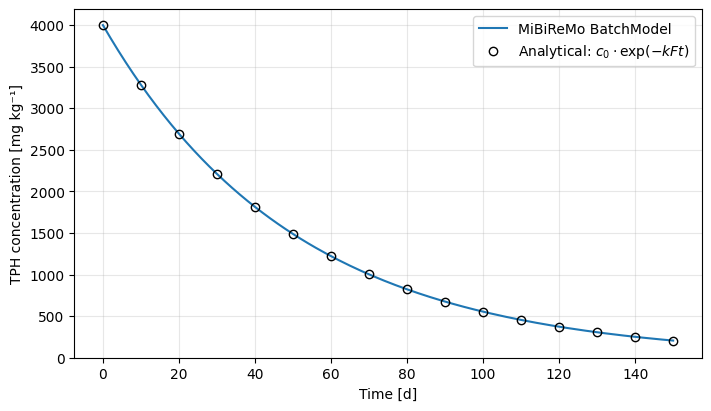

In [29]:
tph = model.kinetic_reactant("Hydrocarbon") * water_content * molar_mass * 1e3  # mg/kg
days = tph.index / DAY
o2_saturation = 8.6 / 32000  # mol/kgw
monod = o2_saturation / (k_o2 + o2_saturation)
print(f"Monod term F = {monod:.3f}, half-life {math.log(2) / (k * monod) / DAY:.0f} d")

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(days, tph[0], label="MiBiReMo BatchModel")
ax.plot(days[::10], content * np.exp(-k * monod * tph.index[::10]), "ko", mfc="none", label=r"Analytical: $c_0 \cdot \exp(-k F t)$")
ax.set(xlabel="Time [d]", ylabel="TPH concentration [mg kg⁻¹]", ylim=(0, None))
ax.grid(alpha=0.3)
ax.legend()
plt.show()